In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from scipy.sparse import load_npz

from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score
)

print("All imports completed successfully!")

All imports completed successfully!


In [3]:
models_dir = Path("../models")

X_train_tfidf = load_npz(models_dir / "X_train_tfidf.npz")
X_test_tfidf = load_npz(models_dir / "X_test_tfidf.npz")

label_encoder = joblib.load(models_dir / "label_encoder.pkl")

y_train_encoded = label_encoder.transform(
    pd.read_csv("../data/xfact_train.csv")["label"].iloc[
        []  # We will load the original split indices next
    ]
)

In [4]:
print("X_train_tfidf:", X_train_tfidf.shape)
print("X_test_tfidf:", X_test_tfidf.shape)

X_train_tfidf: (15263, 50000)
X_test_tfidf: (3816, 50000)


In [5]:
y_train_encoded = np.load(models_dir / "y_train_encoded.npy")
y_test_encoded = np.load(models_dir / "y_test_encoded.npy")

print("Training labels:", y_train_encoded.shape)
print("Testing labels:", y_test_encoded.shape)
print("Number of classes:", len(label_encoder.classes_))

Training labels: (15263,)
Testing labels: (3816,)
Number of classes: 7


In [7]:
lr_model = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    random_state=42,
    solver="saga",
    tol=1e-3
)

lr_model.fit(X_train_tfidf, y_train_encoded)

print("Model training completed!")
print("Iterations used:", lr_model.n_iter_.max())

Model training completed!
Iterations used: 3000


c:\Users\RAM\anaconda3\Allah\envs\truthlens_env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [8]:
y_pred = lr_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test_encoded, y_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_test_encoded, y_pred))
print("Macro F1:", f1_score(y_test_encoded, y_pred, average="macro"))

print("\nClassification Report:")
print(
    classification_report(
        y_test_encoded,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Accuracy: 0.3692348008385744
Balanced Accuracy: 0.4475184919588612
Macro F1: 0.32242967427529523

Classification Report:
                                precision    recall  f1-score   support

complicated/hard to categorise       0.08      0.71      0.15       108
                         false       0.63      0.42      0.51      1503
                  mostly false       0.29      0.78      0.42       170
                   mostly true       0.23      0.22      0.23       276
                         other       0.18      0.44      0.26        71
        partly true/misleading       0.52      0.32      0.40       872
                          true       0.44      0.23      0.30       816

                      accuracy                           0.37      3816
                     macro avg       0.34      0.45      0.32      3816
                  weighted avg       0.49      0.37      0.40      3816



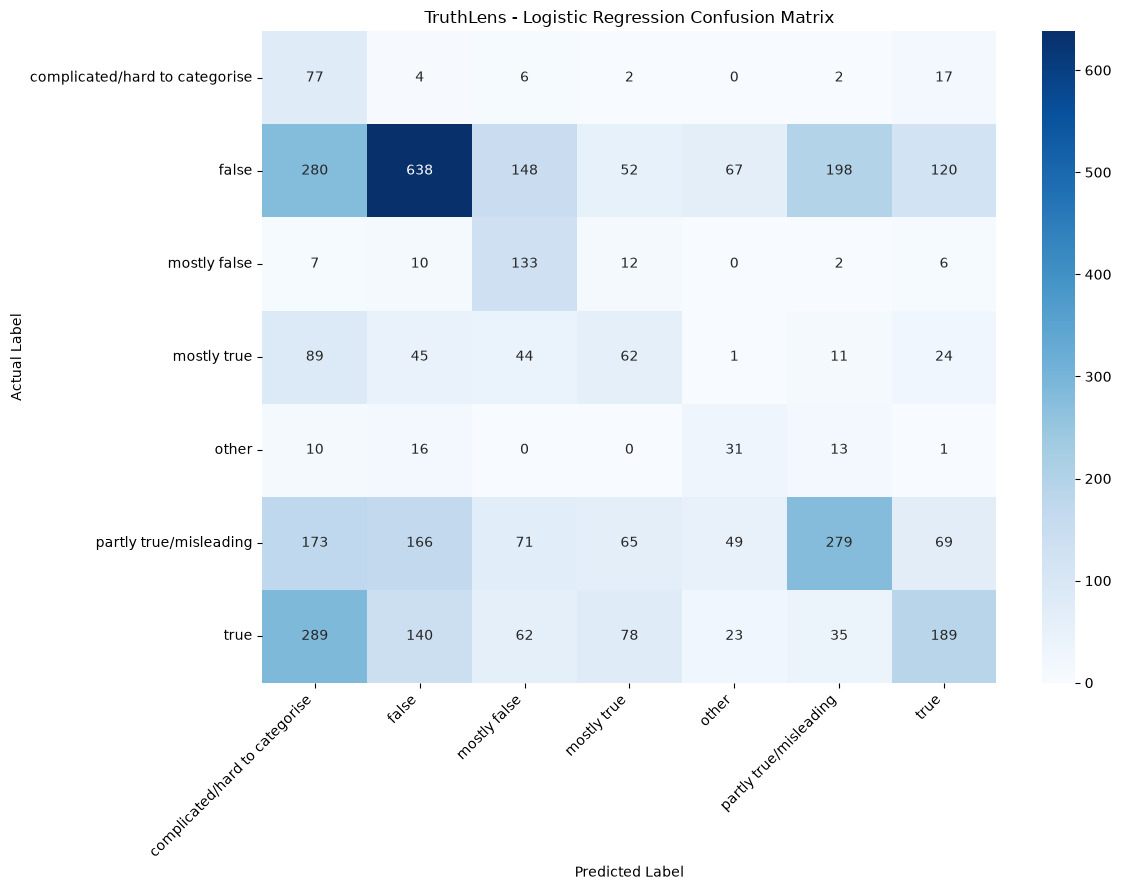

In [9]:
cm = confusion_matrix(
    y_test_encoded,
    y_pred
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("TruthLens - Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

svm_model.fit(X_train_tfidf, y_train_encoded)

print("LinearSVC training completed!")

LinearSVC training completed!


In [12]:
svm_pred = svm_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test_encoded, svm_pred))

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(y_test_encoded, svm_pred)
)

print(
    "Macro F1:",
    f1_score(y_test_encoded, svm_pred, average="macro")
)

print("\nClassification Report:")

print(
    classification_report(
        y_test_encoded,
        svm_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Accuracy: 0.4339622641509434
Balanced Accuracy: 0.38340164018268424
Macro F1: 0.3614300305080234

Classification Report:
                                precision    recall  f1-score   support

complicated/hard to categorise       0.17      0.25      0.20       108
                         false       0.59      0.53      0.56      1503
                  mostly false       0.34      0.48      0.40       170
                   mostly true       0.19      0.25      0.22       276
                         other       0.33      0.39      0.36        71
        partly true/misleading       0.42      0.37      0.39       872
                          true       0.39      0.40      0.40       816

                      accuracy                           0.43      3816
                     macro avg       0.35      0.38      0.36      3816
                  weighted avg       0.45      0.43      0.44      3816



In [13]:
joblib.dump(
    lr_model,
    models_dir / "logistic_regression.pkl"
)

joblib.dump(
    svm_model,
    models_dir / "linear_svc.pkl"
)

print("Both models saved successfully!")

Both models saved successfully!


In [14]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.1, 0.5, 1, 2, 5]
}

grid_search = GridSearchCV(
    LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    ),
    param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_tfidf, y_train_encoded)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Macro F1:", grid_search.best_score_)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Parameters: {'C': 0.1}
Best CV Macro F1: 0.33420398700533366


In [15]:
best_svm = grid_search.best_estimator_

tuned_pred = best_svm.predict(X_test_tfidf)

print("Tuned LinearSVC Results")
print("Accuracy:", accuracy_score(y_test_encoded, tuned_pred))
print(
    "Balanced Accuracy:",
    balanced_accuracy_score(y_test_encoded, tuned_pred)
)
print(
    "Macro F1:",
    f1_score(y_test_encoded, tuned_pred, average="macro")
)

print("\nClassification Report:")

print(
    classification_report(
        y_test_encoded,
        tuned_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Tuned LinearSVC Results
Accuracy: 0.43736897274633124
Balanced Accuracy: 0.44619788207846994
Macro F1: 0.3658359758003026

Classification Report:
                                precision    recall  f1-score   support

complicated/hard to categorise       0.13      0.33      0.18       108
                         false       0.62      0.52      0.56      1503
                  mostly false       0.32      0.66      0.43       170
                   mostly true       0.20      0.33      0.25       276
                         other       0.21      0.55      0.30        71
        partly true/misleading       0.50      0.35      0.41       872
                          true       0.46      0.38      0.42       816

                      accuracy                           0.44      3816
                     macro avg       0.35      0.45      0.37      3816
                  weighted avg       0.49      0.44      0.45      3816



In [16]:
joblib.dump(
    best_svm,
    models_dir / "tuned_linear_svc.pkl"
)

print("Tuned LinearSVC saved successfully!")

Tuned LinearSVC saved successfully!


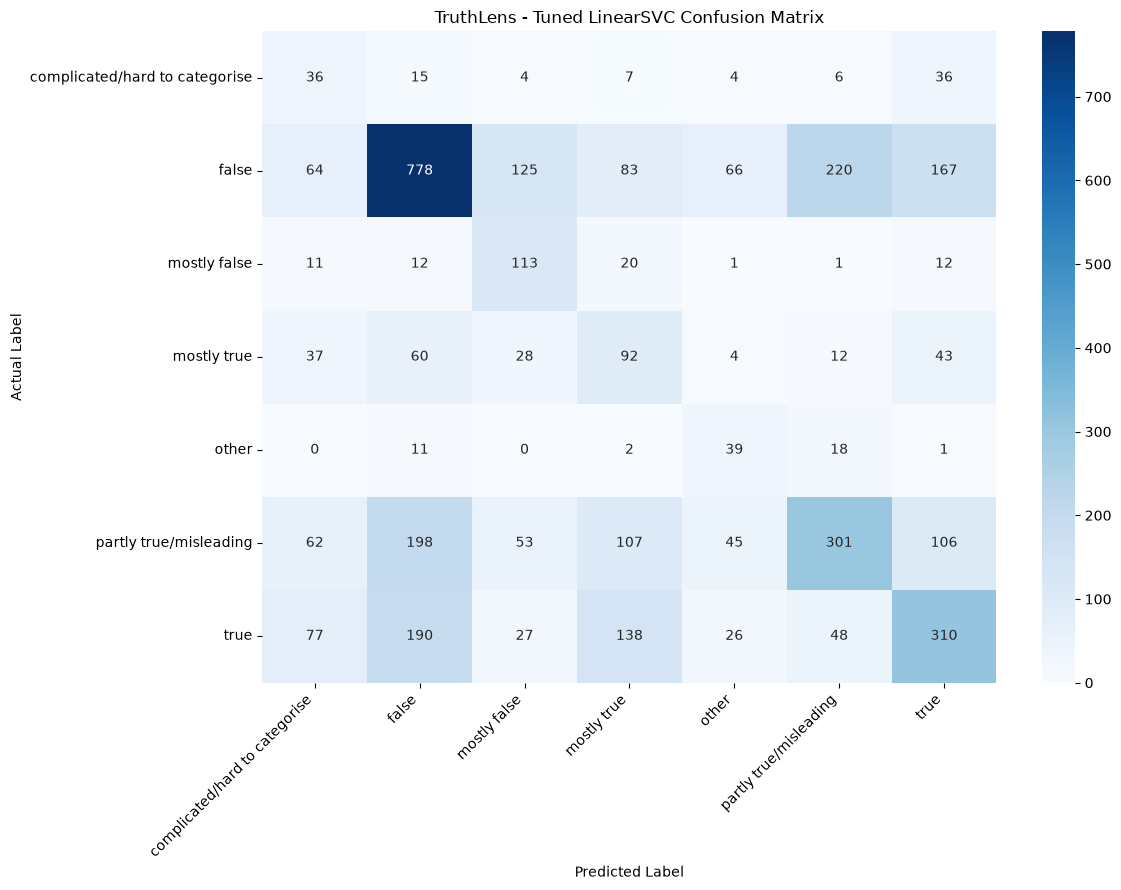

In [17]:
tuned_cm = confusion_matrix(
    y_test_encoded,
    tuned_pred
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    tuned_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("TruthLens - Tuned LinearSVC Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
error_analysis = pd.DataFrame({
    "actual": label_encoder.inverse_transform(y_test_encoded),
    "predicted": label_encoder.inverse_transform(tuned_pred)
})

errors = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
]

print("Total test records:", len(error_analysis))
print("Incorrect predictions:", len(errors))

print("\nMost common classification errors:")

print(
    errors.groupby(["actual", "predicted"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Total test records: 3816
Incorrect predictions: 2147

Most common classification errors:
actual                  predicted                     
false                   partly true/misleading            220
partly true/misleading  false                             198
true                    false                             190
false                   true                              167
true                    mostly true                       138
false                   mostly false                      125
partly true/misleading  mostly true                       107
                        true                              106
false                   mostly true                        83
true                    complicated/hard to categorise     77
dtype: int64


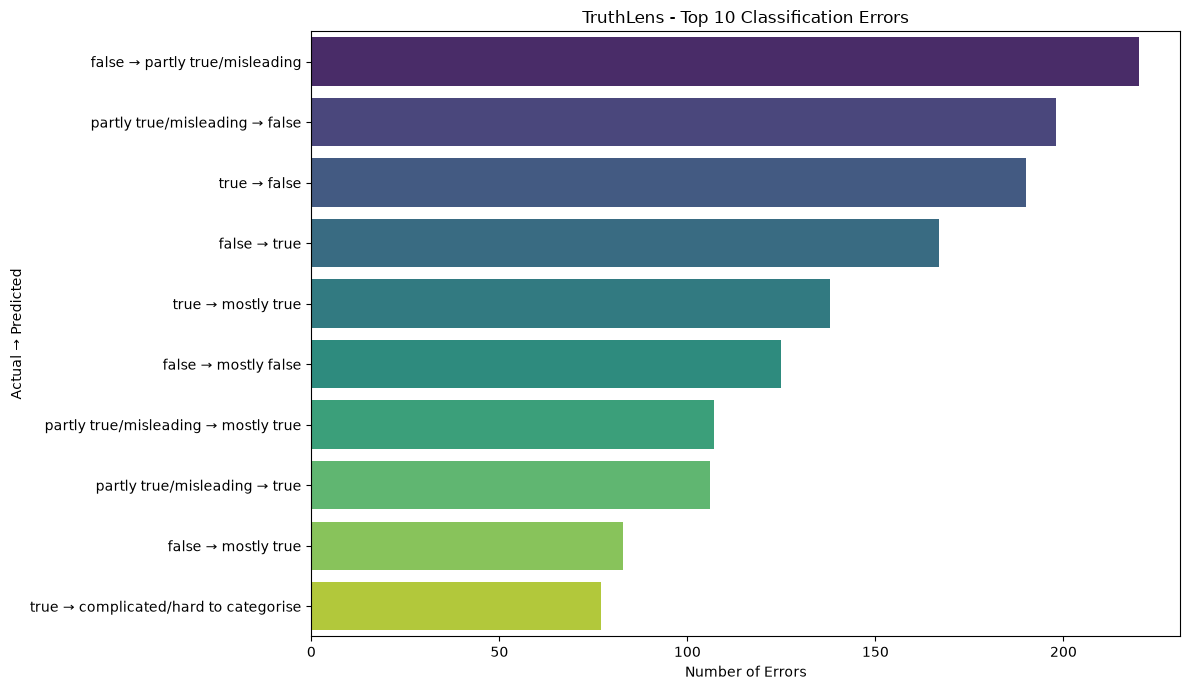

In [19]:
top_errors = (
    errors.groupby(["actual", "predicted"])
    .size()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="count")
)

top_errors["error_type"] = (
    top_errors["actual"] + " → " + top_errors["predicted"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_errors,
    x="count",
    y="error_type",
    hue="error_type",
    palette="viridis",
    legend=False
)

plt.title("TruthLens - Top 10 Classification Errors")
plt.xlabel("Number of Errors")
plt.ylabel("Actual → Predicted")
plt.tight_layout()
plt.show()